In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from collections import Counter

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file == "DATA_Maguire_20180517_ALL.zip":
            print("ZIP PATH:", os.path.join(root, file))

ZIP PATH: /content/drive/MyDrive/DATA_Maguire_20180517_ALL.zip


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/DATA_Maguire_20180517_ALL.zip"
EXTRACT_DIR = "/content/InfraScan_Dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Location:", EXTRACT_DIR)

Dataset extracted successfully!
Location: /content/InfraScan_Dataset


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/InfraScan_Dataset")

print("Top-level folders and files:")

for item in list(DATA_DIR.iterdir())[:30]:
    print(item.name, " | Folder:", item.is_dir())

Top-level folders and files:
DATA_Maguire_20180517_ALL  | Folder: True


In [ ]:
extensions = {".jpg", ".jpeg", ".png", ".bmp"}
image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Total images:", len(image_paths))
print("\nFirst 10 image paths:")

for path in image_paths[:10]:
    print(path)

Total images: 0

First 10 image paths:


In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/DATA_Maguire_20180517_ALL.zip"

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    files = z.namelist()

    print("Total items inside ZIP:", len(files))
    print("\nFirst 40 items:")

    for item in files[:40]:
        print(item)

Total items inside ZIP: 2

First 40 items:
DATA_Maguire_20180517_ALL/ReadMe_SDNET2018 .txt
DATA_Maguire_20180517_ALL/SDNET2018.zip


In [ ]:
from collections import Counter
from pathlib import Path

formats = Counter(
    Path(item).suffix.lower() or "[no extension]"
    for item in files
    if not item.endswith("/")
)

print(formats)

Counter({'.txt': 1, '.zip': 1})


In [ ]:
import zipfile
import os

OUTER_ZIP = "/content/drive/MyDrive/DATA_Maguire_20180517_ALL.zip"
INNER_ZIP = "/content/SDNET2018.zip"
EXTRACT_DIR = "/content/InfraScan_Dataset"

# Outer ZIP se actual dataset ZIP nikalo
with zipfile.ZipFile(OUTER_ZIP, 'r') as z:
    inner_file = next(
        name for name in z.namelist()
        if name.endswith("SDNET2018.zip")
    )

    with z.open(inner_file) as src, open(INNER_ZIP, "wb") as dst:
        dst.write(src.read())

print("Actual dataset ZIP extracted!")

# Actual dataset ki images/folders extract karo
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(INNER_ZIP, 'r') as z:
    print("Items in actual dataset ZIP:", len(z.namelist()))
    z.extractall(EXTRACT_DIR)

print("Dataset extraction complete!")

Actual dataset ZIP extracted!
Items in actual dataset ZIP: 56101
Dataset extraction complete!


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/InfraScan_Dataset")

image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
]

print("Total images:", len(image_paths))
print("\nFirst 10 images:")

for p in image_paths[:10]:
    print(p)

Total images: 56092

First 10 images:
/content/InfraScan_Dataset/W/UW/7134-221.jpg
/content/InfraScan_Dataset/W/UW/7091-5.jpg
/content/InfraScan_Dataset/W/UW/7130-191.jpg
/content/InfraScan_Dataset/W/UW/7100-171.jpg
/content/InfraScan_Dataset/W/UW/7135-105.jpg
/content/InfraScan_Dataset/W/UW/7132-111.jpg
/content/InfraScan_Dataset/W/UW/7090-4.jpg
/content/InfraScan_Dataset/W/UW/7140-33.jpg
/content/InfraScan_Dataset/W/UW/7105-136.jpg
/content/InfraScan_Dataset/W/UW/7075-62.jpg


In [ ]:
from collections import Counter
from pathlib import Path

DATA_DIR = Path("/content/InfraScan_Dataset")

# Image kis folder ke andar hai, uske basis par count
folder_counts = Counter(
    p.parent.name
    for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

print("Images in each folder:\n")

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

print("\nTotal:", sum(folder_counts.values()))

Images in each folder:

CD: 2025
CP: 2608
CW: 3851
UD: 11595
UP: 21726
UW: 14287

Total: 56092


In [ ]:
for p in sorted(DATA_DIR.rglob("*")):
    if p.is_dir():
        print(p.relative_to(DATA_DIR))

D
D/CD
D/UD
DATA_Maguire_20180517_ALL
P
P/CP
P/UP
W
W/CW
W/UW


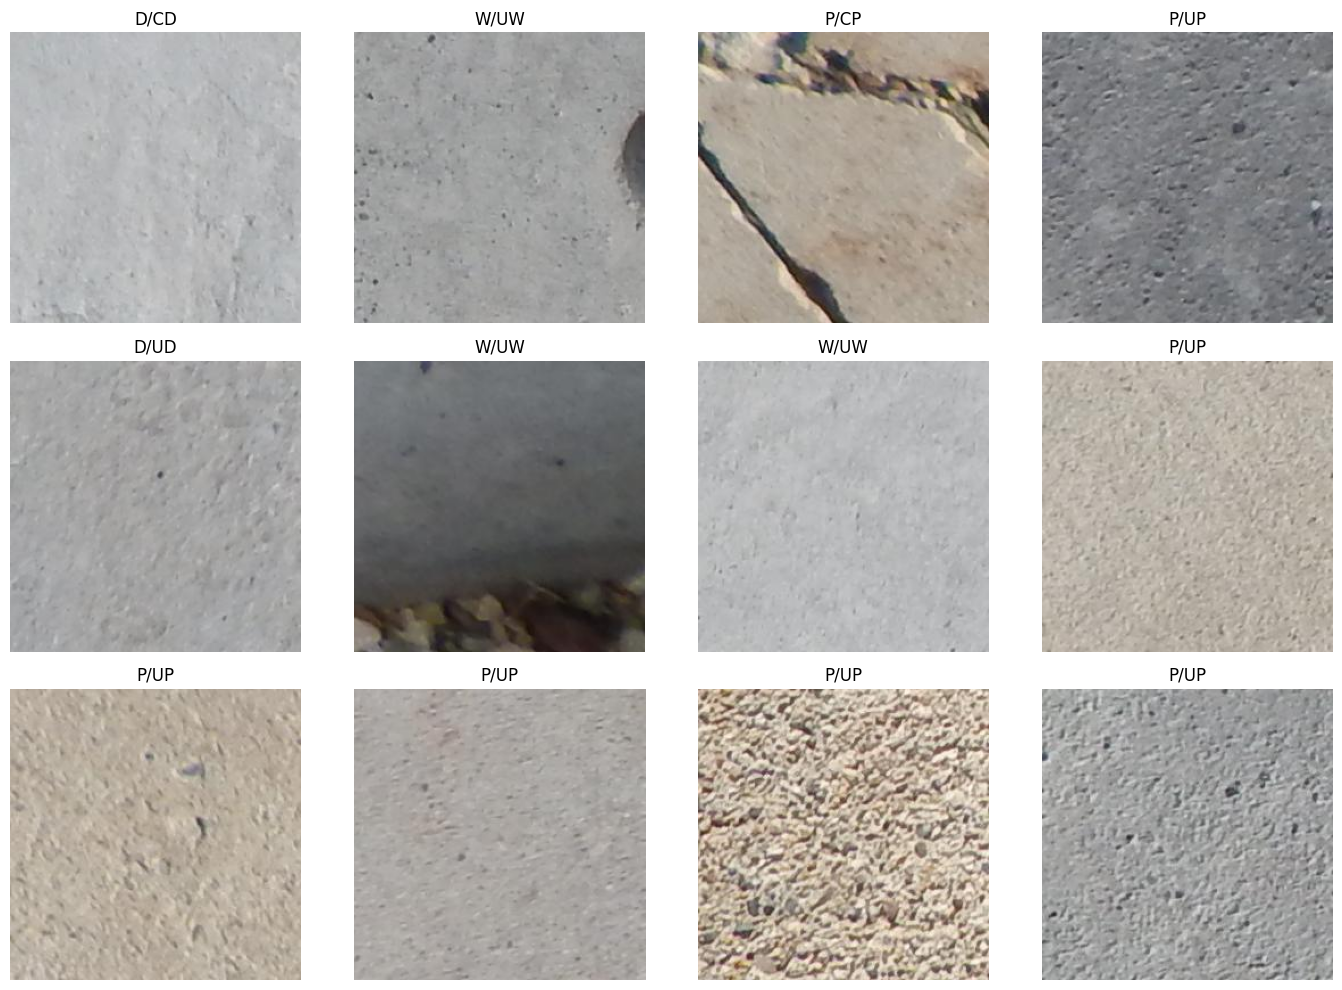

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

sample_paths = random.sample(image_paths, min(12, len(image_paths)))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, path in zip(axes.flat, sample_paths):
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(str(path.relative_to(DATA_DIR).parent))
    ax.axis("off")

for ax in axes.flat[len(sample_paths):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

,Class,Images,Percentage
0,Cracked,8484,15.13
1,Uncracked,47608,84.87


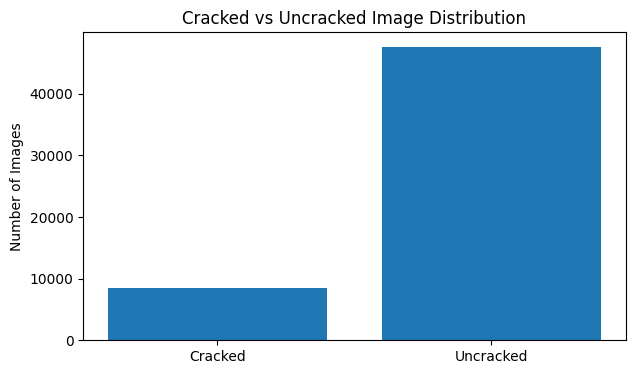

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

class_counts = {
    "Cracked": 2025 + 2608 + 3851,
    "Uncracked": 11595 + 21726 + 14287
}

df_classes = pd.DataFrame({
    "Class": class_counts.keys(),
    "Images": class_counts.values()
})

df_classes["Percentage"] = (
    df_classes["Images"] / df_classes["Images"].sum() * 100
).round(2)

display(df_classes)

plt.figure(figsize=(7, 4))
plt.bar(df_classes["Class"], df_classes["Images"])
plt.title("Cracked vs Uncracked Image Distribution")
plt.ylabel("Number of Images")
plt.show()

,Surface,Cracked,Uncracked,Total
0,Deck,2025,11595,13620
1,Pavement,2608,21726,24334
2,Wall,3851,14287,18138


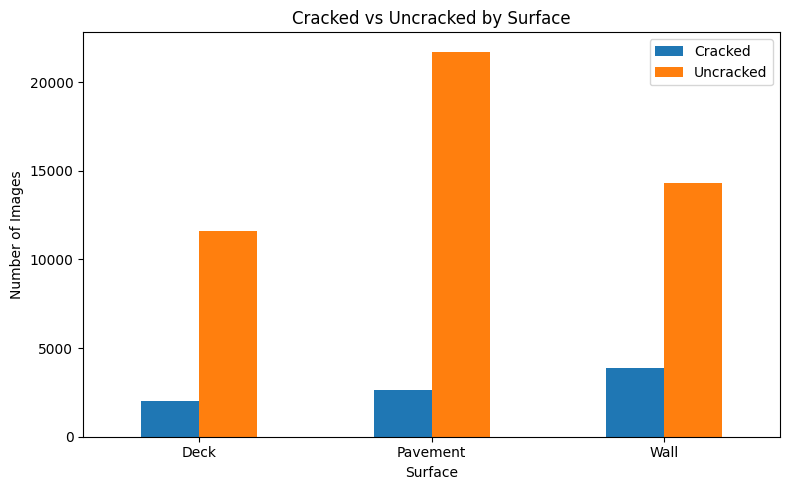

In [ ]:
surface_df = pd.DataFrame({
    "Surface": ["Deck", "Pavement", "Wall"],
    "Cracked": [2025, 2608, 3851],
    "Uncracked": [11595, 21726, 14287]
})

surface_df["Total"] = surface_df["Cracked"] + surface_df["Uncracked"]

display(surface_df)

surface_df.set_index("Surface")[["Cracked", "Uncracked"]].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Cracked vs Uncracked by Surface")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd
from collections import Counter

DATA_DIR = Path("/content/InfraScan_Dataset")

image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
]

records = []
corrupt_images = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            records.append({
                "path": str(path),
                "width": img.width,
                "height": img.height,
                "format": img.format,
                "mode": img.mode,
                "size_kb": round(path.stat().st_size / 1024, 2)
            })
    except Exception:
        corrupt_images.append(str(path))

image_df = pd.DataFrame(records)

print("Total image files:", len(image_paths))
print("Readable images:", len(image_df))
print("Corrupt/unreadable images:", len(corrupt_images))

print("\nImage dimensions:")
display(image_df[["width", "height"]].describe())

print("\nMost common dimensions:")
print(Counter(zip(image_df["width"], image_df["height"])).most_common(10))

print("\nImage formats:")
print(image_df["format"].value_counts())

print("\nColor modes:")
print(image_df["mode"].value_counts())

Total image files: 56092
Readable images: 56092
Corrupt/unreadable images: 0

Image dimensions:


,width,height
count,56092.0,56092.0
mean,256.0,256.0
std,0.0,0.0
min,256.0,256.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0



Most common dimensions:
[((256, 256), 56092)]

Image formats:
format
JPEG    56092
Name: count, dtype: int64

Color modes:
mode
RGB    56092
Name: count, dtype: int64


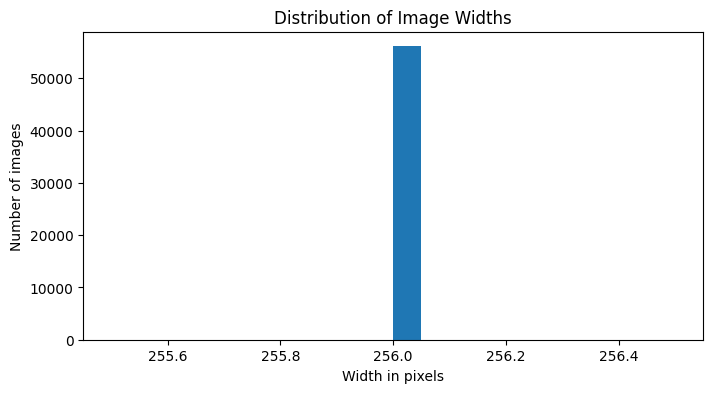

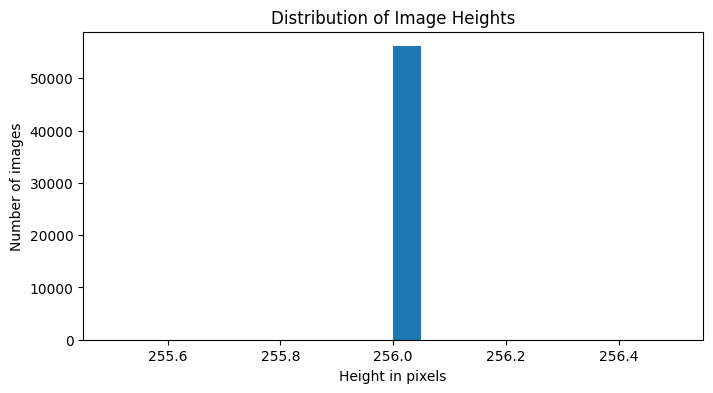

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(image_df["width"], bins=20)
plt.title("Distribution of Image Widths")
plt.xlabel("Width in pixels")
plt.ylabel("Number of images")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(image_df["height"], bins=20)
plt.title("Distribution of Image Heights")
plt.xlabel("Height in pixels")
plt.ylabel("Number of images")
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

quality_records = []

# Har image ko process karenge
for path in tqdm(image_paths, desc="Checking image quality"):
    with Image.open(path) as img:
        gray = np.asarray(
            img.convert("L"),
            dtype=np.float32
        )

    # Average brightness: 0 = black, 255 = white
    brightness = gray.mean()

    # Contrast ka simple measure
    contrast = gray.std()

    # Blur ka rough indicator: Laplacian variance
    # Higher values often indicate more visible edges
    padded = np.pad(gray, 1, mode="edge")

    laplacian = (
        padded[:-2, 1:-1]
        + padded[2:, 1:-1]
        + padded[1:-1, :-2]
        + padded[1:-1, 2:]
        - 4 * gray
    )

    blur_score = laplacian.var()

    quality_records.append({
        "path": str(path),
        "brightness": brightness,
        "contrast": contrast,
        "laplacian_variance": blur_score
    })

quality_df = pd.DataFrame(quality_records)

display(quality_df.describe().round(2))

Checking image quality:   0%|          | 0/56092 [00:00<?, ?it/s]

,brightness,contrast,laplacian_variance
count,56092.00,56092.00,56092.00
mean,162.56,14.98,243.93
std,21.10,10.63,363.23
min,4.55,1.00,0.31
25%,154.07,7.01,32.29
50%,166.56,10.95,78.41
75%,176.60,20.90,294.29
max,247.80,88.86,3284.62


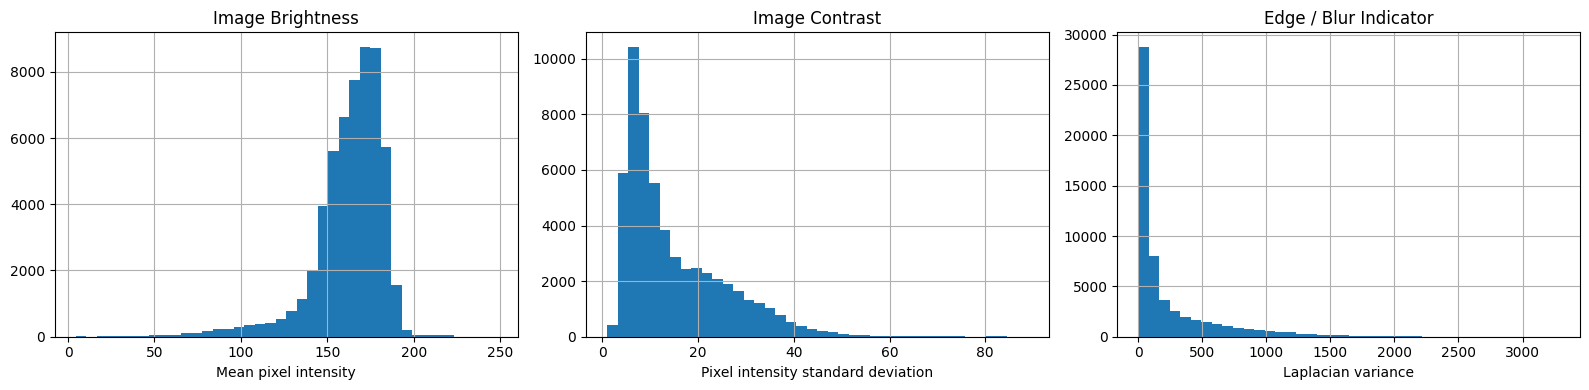

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

quality_df["brightness"].hist(bins=40, ax=axes[0])
axes[0].set_title("Image Brightness")
axes[0].set_xlabel("Mean pixel intensity")

quality_df["contrast"].hist(bins=40, ax=axes[1])
axes[1].set_title("Image Contrast")
axes[1].set_xlabel("Pixel intensity standard deviation")

quality_df["laplacian_variance"].hist(
    bins=40, ax=axes[2]
)
axes[2].set_title("Edge / Blur Indicator")
axes[2].set_xlabel("Laplacian variance")

plt.tight_layout()
plt.show()

In [ ]:
import hashlib
from collections import defaultdict
from tqdm.auto import tqdm

hash_groups = defaultdict(list)

for path in tqdm(image_paths, desc="Finding exact duplicates"):
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    hash_groups[digest].append(str(path))

duplicate_groups = [
    paths for paths in hash_groups.values()
    if len(paths) > 1
]

print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Extra duplicate files:",
    sum(len(g) - 1 for g in duplicate_groups)
)

for group in duplicate_groups[:5]:
    print(group)

Finding exact duplicates:   0%|          | 0/56092 [00:00<?, ?it/s]

Exact duplicate groups: 13
Extra duplicate files: 13
['/content/InfraScan_Dataset/W/UW/7074-105_2.jpg', '/content/InfraScan_Dataset/W/CW/7074-105.jpg']
['/content/InfraScan_Dataset/D/CD/7039-113_2.jpg', '/content/InfraScan_Dataset/D/CD/7039-113.jpg']
['/content/InfraScan_Dataset/D/CD/7039-110.jpg', '/content/InfraScan_Dataset/D/CD/7039-110_2.jpg']
['/content/InfraScan_Dataset/D/CD/7039-111_2.jpg', '/content/InfraScan_Dataset/D/CD/7039-111.jpg']
['/content/InfraScan_Dataset/D/CD/7039-112.jpg', '/content/InfraScan_Dataset/D/UD/7039-112_2.jpg']


In [ ]:
import pandas as pd

duplicate_records = []

for group in duplicate_groups:
    for path in group:
        p = Path(path)

        # Parent folders se surface aur class identify karo
        duplicate_records.append({
            "filename": p.name,
            "surface": p.parent.parent.name,
            "label": p.parent.name,
            "path": str(p),
            "hash": hashlib.sha256(p.read_bytes()).hexdigest()
        })

duplicate_df = pd.DataFrame(duplicate_records)

display(
    duplicate_df.sort_values("hash")[
        ["filename", "surface", "label", "path", "hash"]
    ]
)

,filename,surface,label,path,hash
23,7053-36.jpg,D,UD,/content/InfraScan_Dataset/D/UD/7053-36.jpg,032298f2b453670ffcd9d86576418f789bc268e75f9ed8...
22,7053-36_2.jpg,D,UD,/content/InfraScan_Dataset/D/UD/7053-36_2.jpg,032298f2b453670ffcd9d86576418f789bc268e75f9ed8...
2,7039-113_2.jpg,D,CD,/content/InfraScan_Dataset/D/CD/7039-113_2.jpg,100ed5c4918167180792a76addd82da57a57ee493ba46c...
3,7039-113.jpg,D,CD,/content/InfraScan_Dataset/D/CD/7039-113.jpg,100ed5c4918167180792a76addd82da57a57ee493ba46c...
6,7039-111_2.jpg,D,CD,/content/InfraScan_Dataset/D/CD/7039-111_2.jpg,165edba54700186384701f45fa80f160aed08f7d3f4503...
7,7039-111.jpg,D,CD,/content/InfraScan_Dataset/D/CD/7039-111.jpg,165edba54700186384701f45fa80f160aed08f7d3f4503...
17,7053-89.jpg,D,UD,/content/InfraScan_Dataset/D/UD/7053-89.jpg,2f0a7e57a7864e541e997b7b2a3042ace6f16b045cad36...
16,7053-89_2.jpg,D,UD,/content/InfraScan_Dataset/D/UD/7053-89_2.jpg,2f0a7e57a7864e541e997b7b2a3042ace6f16b045cad36...
10,7053-90.jpg,D,UD,/content/InfraScan_Dataset/D/UD/7053-90.jpg,3792950659aa16111cef63e82bad69c557ac891738b14e...
11,7053-90_2.jpg,D,UD,/content/InfraScan_Dataset/D/UD/7053-90_2.jpg,3792950659aa16111cef63e82bad69c557ac891738b14e...


In [ ]:
conflicts = []

for digest, group in duplicate_df.groupby("hash"):
    if group["label"].nunique() > 1:
        conflicts.append(group)

print("Duplicate groups with conflicting labels:", len(conflicts))

for group in conflicts:
    print("\n--- Conflict ---")
    display(group[["filename", "surface", "label", "path"]])

Duplicate groups with conflicting labels: 2

--- Conflict ---


,filename,surface,label,path
8,7039-112.jpg,D,CD,/content/InfraScan_Dataset/D/CD/7039-112.jpg
9,7039-112_2.jpg,D,UD,/content/InfraScan_Dataset/D/UD/7039-112_2.jpg



--- Conflict ---


,filename,surface,label,path
0,7074-105_2.jpg,W,UW,/content/InfraScan_Dataset/W/UW/7074-105_2.jpg
1,7074-105.jpg,W,CW,/content/InfraScan_Dataset/W/CW/7074-105.jpg


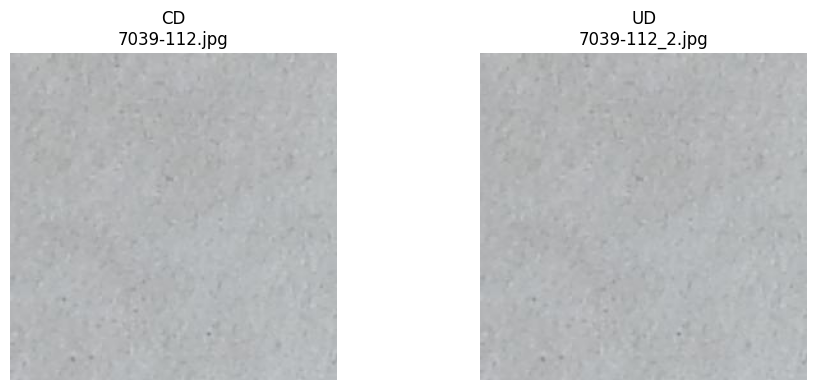

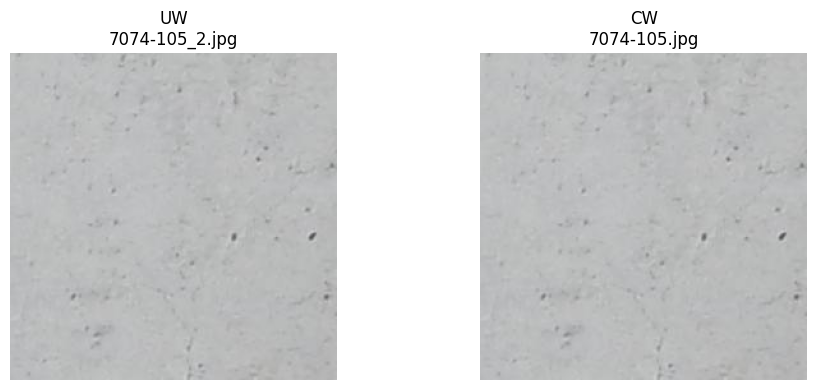

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

for group in conflicts[:5]:
    paths = group["path"].tolist()

    fig, axes = plt.subplots(1, len(paths), figsize=(5 * len(paths), 4))

    if len(paths) == 1:
        axes = [axes]

    for ax, path in zip(axes, paths):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(f"{Path(path).parent.name}\n{Path(path).name}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

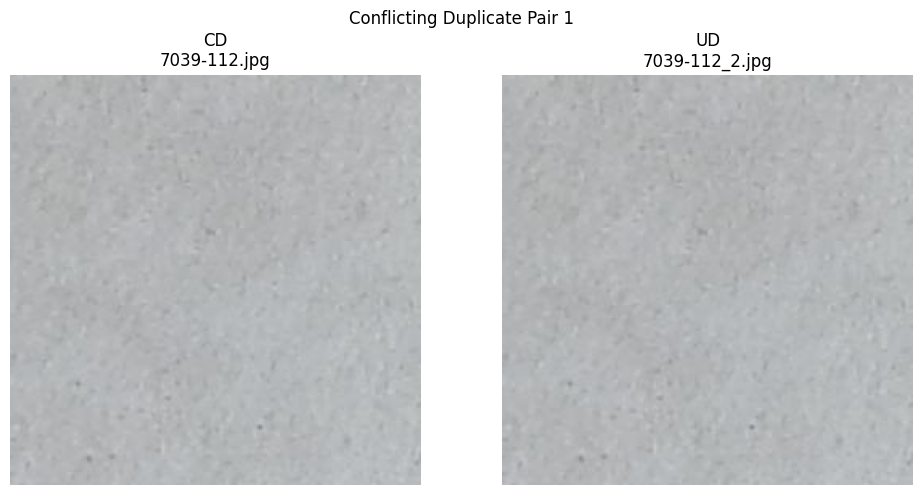

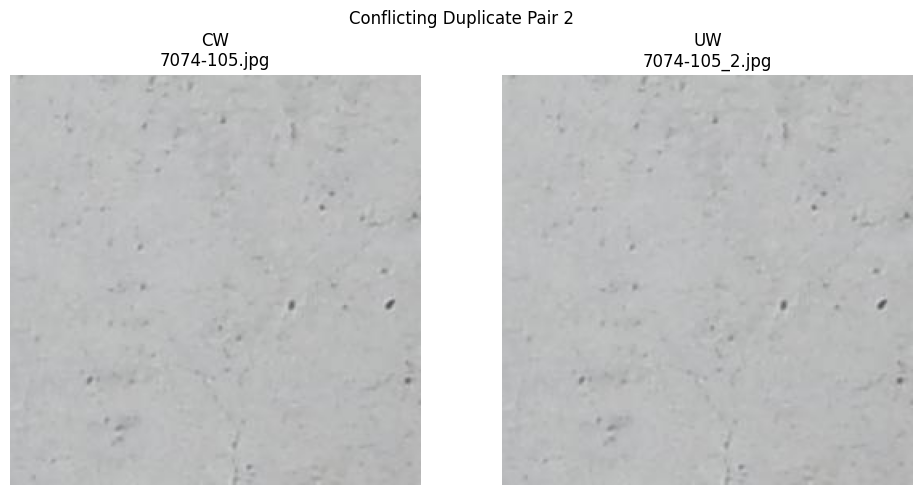

In [ ]:

from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

conflict_pairs = [
    (
        "/content/InfraScan_Dataset/D/CD/7039-112.jpg",
        "/content/InfraScan_Dataset/D/UD/7039-112_2.jpg"
    ),
    (
        "/content/InfraScan_Dataset/W/CW/7074-105.jpg",
        "/content/InfraScan_Dataset/W/UW/7074-105_2.jpg"
    )
]

for pair_num, paths in enumerate(conflict_pairs, start=1):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, path in zip(axes, paths):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{Path(path).parent.name}\n{Path(path).name}"
        )
        ax.axis("off")

    fig.suptitle(f"Conflicting Duplicate Pair {pair_num}")
    plt.tight_layout()
    plt.show()


In [ ]:

import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

DATA_DIR = Path("/content/InfraScan_Dataset")

quality_rows = []

image_files = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

for path in tqdm(image_files, desc="Analyzing image quality"):
    img = cv2.imread(str(path))

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Mean pixel intensity: approximate brightness (0–255)
    brightness = float(np.mean(gray))

    # Standard deviation: approximate grayscale contrast
    contrast = float(np.std(gray))

    # Laplacian variance: a rough sharpness/blur indicator
    blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())

    label_code = path.parent.name
    surface_code = path.parent.parent.name

    quality_rows.append({
        "filename": path.name,
        "surface": surface_code,
        "label_code": label_code,
        "binary_label": (
            "Cracked" if label_code.startswith("C")
            else "Uncracked" if label_code.startswith("U")
            else "Unknown"
        ),
        "brightness": brightness,
        "contrast": contrast,
        "blur_score": blur_score,
        "path": str(path)
    })

quality_df = pd.DataFrame(quality_rows)

print("Images analyzed:", len(quality_df))
display(
    quality_df[
        ["brightness", "contrast", "blur_score"]
    ].describe().round(2)
)


Analyzing image quality:   0%|          | 0/56092 [00:00<?, ?it/s]

Images analyzed: 56092


,brightness,contrast,blur_score
count,56092.00,56092.00,56092.00
mean,162.56,14.98,248.32
std,21.10,10.63,369.69
min,4.55,1.00,0.31
25%,154.07,7.01,32.82
50%,166.56,10.95,79.82
75%,176.60,20.90,299.72
max,247.80,88.86,3332.03


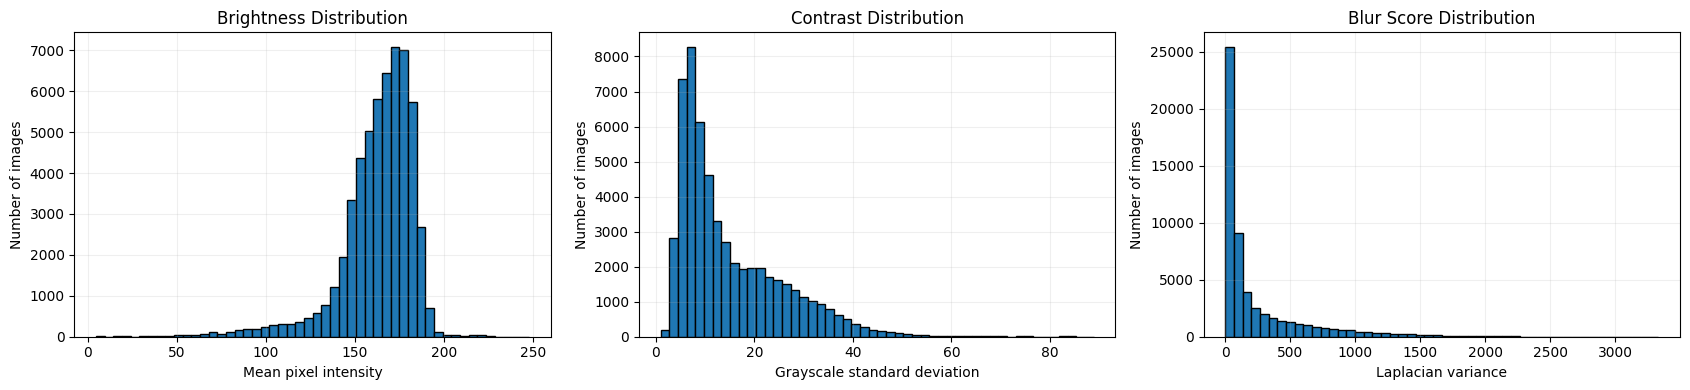

In [ ]:

import matplotlib.pyplot as plt

metrics = [
    ("brightness", "Brightness Distribution", "Mean pixel intensity"),
    ("contrast", "Contrast Distribution", "Grayscale standard deviation"),
    ("blur_score", "Blur Score Distribution", "Laplacian variance")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, (column, title, xlabel) in zip(axes, metrics):
    ax.hist(quality_df[column].dropna(), bins=50, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of images")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [ ]:

print("10 darkest images:")
display(
    quality_df.nsmallest(10, "brightness")[
        ["filename", "label_code", "brightness", "path"]
    ]
)

print("10 highest-brightness images:")
display(
    quality_df.nlargest(10, "brightness")[
        ["filename", "label_code", "brightness", "path"]
    ]
)

print("10 lowest-contrast images:")
display(
    quality_df.nsmallest(10, "contrast")[
        ["filename", "label_code", "contrast", "path"]
    ]
)

print("10 lowest blur-score images (potentially less sharp):")
display(
    quality_df.nsmallest(10, "blur_score")[
        ["filename", "label_code", "blur_score", "path"]
    ]
)


10 darkest images:


,filename,label_code,brightness,path
26121,7015-16.jpg,UD,4.552597,/content/InfraScan_Dataset/D/UD/7015-16.jpg
22925,7015-18.jpg,UD,4.607422,/content/InfraScan_Dataset/D/UD/7015-18.jpg
27662,7014-15.jpg,UD,4.728806,/content/InfraScan_Dataset/D/UD/7014-15.jpg
27162,7014-34.jpg,UD,5.120407,/content/InfraScan_Dataset/D/UD/7014-34.jpg
31332,7014-10.jpg,UD,5.196075,/content/InfraScan_Dataset/D/UD/7014-10.jpg
29766,7014-9.jpg,UD,5.316330,/content/InfraScan_Dataset/D/UD/7014-9.jpg
24831,7014-11.jpg,UD,5.325836,/content/InfraScan_Dataset/D/UD/7014-11.jpg
31721,7015-17.jpg,UD,5.352478,/content/InfraScan_Dataset/D/UD/7015-17.jpg
29268,7014-16.jpg,UD,7.279785,/content/InfraScan_Dataset/D/UD/7014-16.jpg
21702,7014-12.jpg,UD,7.360443,/content/InfraScan_Dataset/D/UD/7014-12.jpg


10 highest-brightness images:


,filename,label_code,brightness,path
43824,081-233.jpg,UP,247.798340,/content/InfraScan_Dataset/P/UP/081-233.jpg
39340,081-234.jpg,UP,240.664536,/content/InfraScan_Dataset/P/UP/081-234.jpg
48714,081-232.jpg,UP,234.224426,/content/InfraScan_Dataset/P/UP/081-232.jpg
44548,081-216.jpg,UP,234.176315,/content/InfraScan_Dataset/P/UP/081-216.jpg
41140,001-15.jpg,UP,227.559479,/content/InfraScan_Dataset/P/UP/001-15.jpg
46077,056-6.jpg,UP,227.201370,/content/InfraScan_Dataset/P/UP/056-6.jpg
38022,056-5.jpg,UP,226.820602,/content/InfraScan_Dataset/P/UP/056-5.jpg
50645,001-16.jpg,UP,225.807785,/content/InfraScan_Dataset/P/UP/001-16.jpg
54112,001-107.jpg,CP,224.186783,/content/InfraScan_Dataset/P/CP/001-107.jpg
52759,001-87.jpg,UP,223.499069,/content/InfraScan_Dataset/P/UP/001-87.jpg


10 lowest-contrast images:


,filename,label_code,contrast,path
22925,7015-18.jpg,UD,1.000639,/content/InfraScan_Dataset/D/UD/7015-18.jpg
26121,7015-16.jpg,UD,1.346193,/content/InfraScan_Dataset/D/UD/7015-16.jpg
31332,7014-10.jpg,UD,1.383433,/content/InfraScan_Dataset/D/UD/7014-10.jpg
643,7123-122.jpg,UW,1.628089,/content/InfraScan_Dataset/W/UW/7123-122.jpg
24831,7014-11.jpg,UD,1.665914,/content/InfraScan_Dataset/D/UD/7014-11.jpg
2520,7123-90.jpg,UW,1.691027,/content/InfraScan_Dataset/W/UW/7123-90.jpg
27662,7014-15.jpg,UD,1.695245,/content/InfraScan_Dataset/D/UD/7014-15.jpg
9190,7123-124.jpg,UW,1.713607,/content/InfraScan_Dataset/W/UW/7123-124.jpg
11115,7122-2.jpg,UW,1.731474,/content/InfraScan_Dataset/W/UW/7122-2.jpg
1961,7123-140.jpg,UW,1.735984,/content/InfraScan_Dataset/W/UW/7123-140.jpg


10 lowest blur-score images (potentially less sharp):


,filename,label_code,blur_score,path
22925,7015-18.jpg,UD,0.309296,/content/InfraScan_Dataset/D/UD/7015-18.jpg
31332,7014-10.jpg,UD,0.371704,/content/InfraScan_Dataset/D/UD/7014-10.jpg
26121,7015-16.jpg,UD,0.418838,/content/InfraScan_Dataset/D/UD/7015-16.jpg
31721,7015-17.jpg,UD,0.437012,/content/InfraScan_Dataset/D/UD/7015-17.jpg
27662,7014-15.jpg,UD,0.517929,/content/InfraScan_Dataset/D/UD/7014-15.jpg
24831,7014-11.jpg,UD,0.582016,/content/InfraScan_Dataset/D/UD/7014-11.jpg
21702,7014-12.jpg,UD,0.606659,/content/InfraScan_Dataset/D/UD/7014-12.jpg
29766,7014-9.jpg,UD,0.707885,/content/InfraScan_Dataset/D/UD/7014-9.jpg
31100,7014-54.jpg,UD,1.187345,/content/InfraScan_Dataset/D/UD/7014-54.jpg
29268,7014-16.jpg,UD,1.253601,/content/InfraScan_Dataset/D/UD/7014-16.jpg


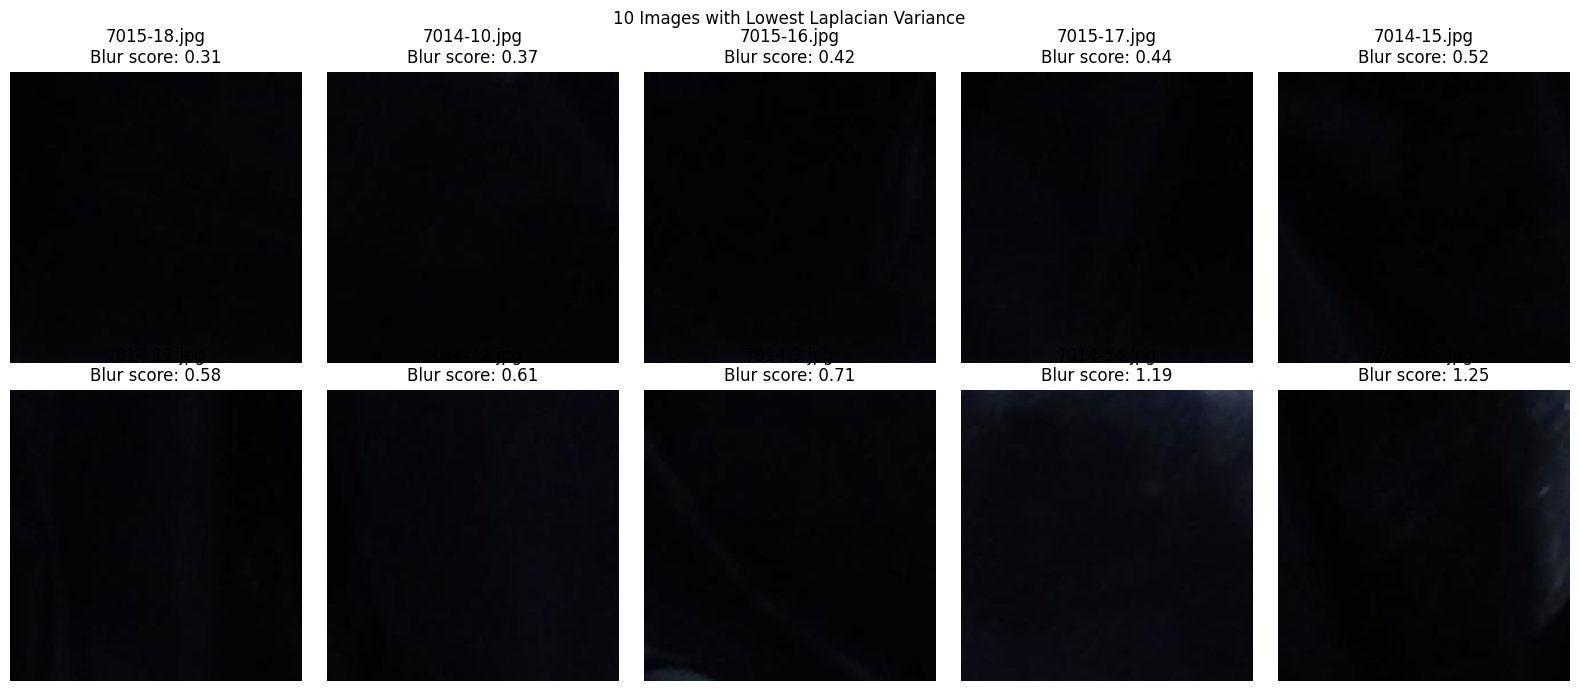

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt
import math

suspect_images = quality_df.nsmallest(10, "blur_score")

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

for ax, (_, row) in zip(axes, suspect_images.iterrows()):
    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f'{row["filename"]}\n'
        f'Blur score: {row["blur_score"]:.2f}'
    )
    ax.axis("off")

plt.suptitle("10 Images with Lowest Laplacian Variance")
plt.tight_layout()
plt.show()


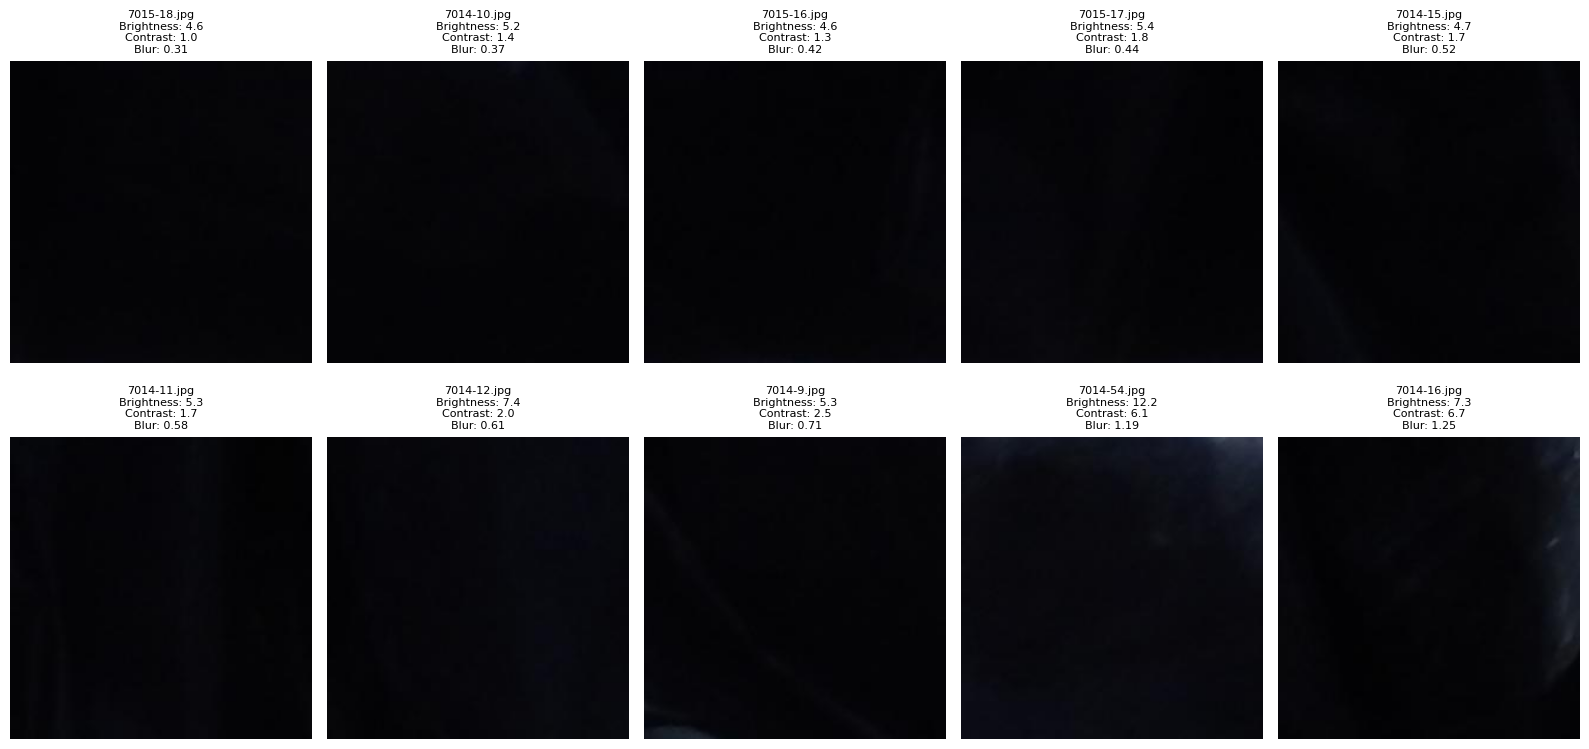

In [ ]:

import cv2
import matplotlib.pyplot as plt
from PIL import Image

suspect_images = quality_df.nsmallest(10, "blur_score")

fig, axes = plt.subplots(2, 5, figsize=(16, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, suspect_images.iterrows()):
    img = cv2.imread(row["path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Original image ko hi display kar rahe hain; enhance nahi kar rahe
    ax.imshow(img)
    ax.set_title(
        f'{row["filename"]}\n'
        f'Brightness: {row["brightness"]:.1f}\n'
        f'Contrast: {row["contrast"]:.1f}\n'
        f'Blur: {row["blur_score"]:.2f}',
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Class-wise quality summary
class_quality = (
    quality_df.groupby("binary_label")
    [["brightness", "contrast", "blur_score"]]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(class_quality)

# Surface-wise quality summary
surface_quality = (
    quality_df.groupby("surface")
    [["brightness", "contrast", "blur_score"]]
    .median()
    .round(2)
)

print("Median image quality by surface:")
display(surface_quality)


brightness                contrast               blur_score  \
                   mean  median    std     mean median    std       mean   
binary_label                                                               
Cracked          167.45  171.45  17.27    14.86  10.93  10.70     230.25   
Uncracked        161.69  165.65  21.60    15.00  10.96  10.62     251.54   

                             
             median     std  
binary_label                 
Cracked       81.05  362.04  
Uncracked     79.43  370.94

Median image quality by surface:


,brightness,contrast,blur_score
surface,,,
D,177.62,7.49,47.23
P,155.54,21.67,367.88
W,168.51,7.73,34.86


In [ ]:

!pip -q install ImageHash


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 13.7 MB/s eta 0:00:00


In [ ]:

from PIL import Image
import imagehash
from pathlib import Path
from tqdm.auto import tqdm

DATA_DIR = Path("/content/InfraScan_Dataset")

image_files = sorted([
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

hashes = {}

for path in tqdm(image_files, desc="Computing perceptual hashes"):
    try:
        with Image.open(path) as img:
            hashes[str(path)] = imagehash.phash(img.convert("RGB"))
    except Exception as e:
        print("Could not process:", path, e)

print("Images hashed:", len(hashes))
print("Example hash:", next(iter(hashes.items())))


Computing perceptual hashes:   0%|          | 0/56092 [00:00<?, ?it/s]

Images hashed: 56092
Example hash: ('/content/InfraScan_Dataset/D/CD/7001-115.jpg', array([[ True, False, False,  True, False,  True,  True, False],
       [False,  True, False, False,  True,  True,  True,  True],
       [ True,  True, False, False, False, False,  True,  True],
       [ True, False,  True,  True,  True,  True, False, False],
       [ True,  True,  True, False,  True,  True,  True,  True],
       [False,  True,  True, False, False, False, False, False],
       [False,  True, False, False, False,  True, False,  True],
       [False,  True,  True, False, False, False, False, False]]))


In [ ]:

from collections import defaultdict
from itertools import combinations
import pandas as pd

# Perceptual hashes ko fixed-length hexadecimal strings mein convert karo
hash_buckets = defaultdict(list)

for path, phash in hashes.items():
    hash_buckets[str(phash)].append(path)

# Same perceptual hash wali images collect karo
candidate_pairs = []

for paths in hash_buckets.values():
    if len(paths) > 1:
        for path1, path2 in combinations(paths, 2):
            candidate_pairs.append({
                "path1": path1,
                "path2": path2,
                "hash_distance": 0
            })

near_duplicate_df = pd.DataFrame(
    candidate_pairs,
    columns=["path1", "path2", "hash_distance"]
)

print("Images processed:", len(hashes))
print("Exact perceptual-hash candidate pairs:", len(near_duplicate_df))
display(near_duplicate_df.head(20))


Images processed: 56092
Exact perceptual-hash candidate pairs: 18


,path1,path2,hash_distance
0,/content/InfraScan_Dataset/D/CD/7039-110.jpg,/content/InfraScan_Dataset/D/CD/7039-110_2.jpg,0
1,/content/InfraScan_Dataset/D/CD/7039-111.jpg,/content/InfraScan_Dataset/D/CD/7039-111_2.jpg,0
2,/content/InfraScan_Dataset/D/CD/7039-112.jpg,/content/InfraScan_Dataset/D/UD/7039-112_2.jpg,0
3,/content/InfraScan_Dataset/D/CD/7039-113.jpg,/content/InfraScan_Dataset/D/CD/7039-113_2.jpg,0
4,/content/InfraScan_Dataset/D/UD/7033-239.jpg,/content/InfraScan_Dataset/P/CP/062-104.jpg,0
5,/content/InfraScan_Dataset/D/UD/7053-17.jpg,/content/InfraScan_Dataset/D/UD/7053-17_2.jpg,0
6,/content/InfraScan_Dataset/D/UD/7053-18.jpg,/content/InfraScan_Dataset/D/UD/7053-18_2.jpg,0
7,/content/InfraScan_Dataset/D/UD/7053-35.jpg,/content/InfraScan_Dataset/D/UD/7053-35_2.jpg,0
8,/content/InfraScan_Dataset/D/UD/7053-36.jpg,/content/InfraScan_Dataset/D/UD/7053-36_2.jpg,0
9,/content/InfraScan_Dataset/D/UD/7053-53.jpg,/content/InfraScan_Dataset/D/UD/7053-53_2.jpg,0


In [ ]:
# Sabhi image pairs ke perceptual hashes compare karna
# Sirf nearby hash values wale candidates report honge.

from itertools import combinations
import pandas as pd

paths = list(hashes.keys())
hash_values = list(hashes.values())

# Existing identical-hash candidates ke alawa,
# small hash distance wale pairs bhi find karna.
# Efficient block-based search use karenge in the next step.

print("Total images:", len(paths))
print("Exact perceptual-hash candidate pairs:", len(near_duplicate_df))
print("Next: Hamming-distance based candidate search")

Total images: 56092
Exact perceptual-hash candidate pairs: 18
Next: Hamming-distance based candidate search


In [ ]:

import numpy as np
import pandas as pd
from collections import defaultdict
from itertools import combinations

# Perceptual hashes ko 64-bit integers mein convert karo
paths = list(hashes.keys())
hash_ints = [
    int(str(hashes[p]), 16)
    for p in paths
]

# Hash ke 4 chunks (16 bits each) par candidate indexing
# Distance <= 5 ke liye 4 chunks mein se kam se kam
# ek chunk identical hona chahiye.
buckets = defaultdict(list)

for i, value in enumerate(hash_ints):
    for chunk in range(4):
        part = (value >> (16 * chunk)) & 0xFFFF
        buckets[(chunk, part)].append(i)

candidate_indices = set()

for indices in buckets.values():
    if len(indices) > 1:
        for i, j in combinations(indices, 2):
            if i < j:
                candidate_indices.add((i, j))

# Candidates ke beech exact Hamming distance calculate karo
results = []

for i, j in candidate_indices:
    distance = (hash_ints[i] ^ hash_ints[j]).bit_count()

    if distance <= 5:
        results.append({
            "path1": paths[i],
            "path2": paths[j],
            "hash_distance": distance,
            "label1": paths[i].split("/")[-2],
            "label2": paths[j].split("/")[-2]
        })

near_duplicates = pd.DataFrame(
    results,
    columns=["path1", "path2", "hash_distance", "label1", "label2"]
)

if not near_duplicates.empty:
    near_duplicates = near_duplicates.sort_values(
        "hash_distance"
    ).reset_index(drop=True)

print("Images processed:", len(paths))
print("Candidate pairs checked:", len(candidate_indices))
print("Pairs with Hamming distance <= 5:", len(near_duplicates))

display(near_duplicates.head(30))


Images processed: 56092
Candidate pairs checked: 178657
Pairs with Hamming distance <= 5: 300


,path1,path2,hash_distance,label1,label2
0,/content/InfraScan_Dataset/D/UD/7053-17.jpg,/content/InfraScan_Dataset/D/UD/7053-17_2.jpg,0,UD,UD
1,/content/InfraScan_Dataset/D/CD/7039-112.jpg,/content/InfraScan_Dataset/D/UD/7039-112_2.jpg,0,CD,UD
2,/content/InfraScan_Dataset/D/CD/7039-111.jpg,/content/InfraScan_Dataset/D/CD/7039-111_2.jpg,0,CD,CD
3,/content/InfraScan_Dataset/P/CP/104-41.jpg,/content/InfraScan_Dataset/W/UW/7105-14.jpg,0,CP,UW
4,/content/InfraScan_Dataset/D/UD/7053-35.jpg,/content/InfraScan_Dataset/D/UD/7053-35_2.jpg,0,UD,UD
5,/content/InfraScan_Dataset/D/UD/7053-89.jpg,/content/InfraScan_Dataset/D/UD/7053-89_2.jpg,0,UD,UD
6,/content/InfraScan_Dataset/D/UD/7053-53.jpg,/content/InfraScan_Dataset/D/UD/7053-53_2.jpg,0,UD,UD
7,/content/InfraScan_Dataset/D/UD/7053-18.jpg,/content/InfraScan_Dataset/D/UD/7053-18_2.jpg,0,UD,UD
8,/content/InfraScan_Dataset/P/CP/104-41.jpg,/content/InfraScan_Dataset/W/CW/7119-69.jpg,0,CP,CW
9,/content/InfraScan_Dataset/D/UD/7053-90.jpg,/content/InfraScan_Dataset/D/UD/7053-90_2.jpg,0,UD,UD


In [ ]:

# 1. Distance-wise summary
print("Pairs by Hamming distance:")
display(
    near_duplicates["hash_distance"]
    .value_counts()
    .sort_index()
    .rename_axis("Hamming distance")
    .reset_index(name="Number of pairs")
)

# 2. Different binary-label candidates
def to_binary(label):
    if label.startswith("C"):
        return "Cracked"
    if label.startswith("U"):
        return "Uncracked"
    return "Unknown"

near_duplicates["binary1"] = near_duplicates["label1"].apply(to_binary)
near_duplicates["binary2"] = near_duplicates["label2"].apply(to_binary)

cross_label = near_duplicates[
    near_duplicates["binary1"] != near_duplicates["binary2"]
].copy()

print("Pairs with different binary labels:", len(cross_label))
print("Showing first 30 candidates:")
display(
    cross_label.sort_values("hash_distance").head(30)
)


Pairs by Hamming distance:


,Hamming distance,Number of pairs
0,0,18
1,2,87
2,4,195


Pairs with different binary labels: 122
Showing first 30 candidates:


,path1,path2,hash_distance,label1,label2,binary1,binary2
1,/content/InfraScan_Dataset/D/CD/7039-112.jpg,/content/InfraScan_Dataset/D/UD/7039-112_2.jpg,0,CD,UD,Cracked,Uncracked
3,/content/InfraScan_Dataset/P/CP/104-41.jpg,/content/InfraScan_Dataset/W/UW/7105-14.jpg,0,CP,UW,Cracked,Uncracked
11,/content/InfraScan_Dataset/D/UD/7033-239.jpg,/content/InfraScan_Dataset/P/CP/062-104.jpg,0,UD,CP,Uncracked,Cracked
15,/content/InfraScan_Dataset/W/CW/7119-69.jpg,/content/InfraScan_Dataset/W/UW/7105-14.jpg,0,CW,UW,Cracked,Uncracked
16,/content/InfraScan_Dataset/W/CW/7074-105.jpg,/content/InfraScan_Dataset/W/UW/7074-105_2.jpg,0,CW,UW,Cracked,Uncracked
18,/content/InfraScan_Dataset/P/UP/030-152.jpg,/content/InfraScan_Dataset/W/CW/7119-69.jpg,2,UP,CW,Uncracked,Cracked
20,/content/InfraScan_Dataset/P/CP/092-63.jpg,/content/InfraScan_Dataset/P/UP/033-12.jpg,2,CP,UP,Cracked,Uncracked
21,/content/InfraScan_Dataset/P/CP/027-59_2.jpg,/content/InfraScan_Dataset/P/UP/063-71.jpg,2,CP,UP,Cracked,Uncracked
23,/content/InfraScan_Dataset/P/CP/062-104.jpg,/content/InfraScan_Dataset/P/UP/058-224.jpg,2,CP,UP,Cracked,Uncracked
25,/content/InfraScan_Dataset/P/CP/030-174.jpg,/content/InfraScan_Dataset/P/UP/033-12.jpg,2,CP,UP,Cracked,Uncracked


In [ ]:
print("Total near-duplicate candidate pairs:", len(near_duplicates))
print("Exact perceptual matches:",
      (near_duplicates["hash_distance"] == 0).sum())
print("Different binary-label pairs:", len(cross_label))

display(
    cross_label.sort_values("hash_distance").head(20)
)

Total near-duplicate candidate pairs: 300
Exact perceptual matches: 18
Different binary-label pairs: 122


,path1,path2,hash_distance,label1,label2,binary1,binary2
1,/content/InfraScan_Dataset/D/CD/7039-112.jpg,/content/InfraScan_Dataset/D/UD/7039-112_2.jpg,0,CD,UD,Cracked,Uncracked
3,/content/InfraScan_Dataset/P/CP/104-41.jpg,/content/InfraScan_Dataset/W/UW/7105-14.jpg,0,CP,UW,Cracked,Uncracked
11,/content/InfraScan_Dataset/D/UD/7033-239.jpg,/content/InfraScan_Dataset/P/CP/062-104.jpg,0,UD,CP,Uncracked,Cracked
15,/content/InfraScan_Dataset/W/CW/7119-69.jpg,/content/InfraScan_Dataset/W/UW/7105-14.jpg,0,CW,UW,Cracked,Uncracked
16,/content/InfraScan_Dataset/W/CW/7074-105.jpg,/content/InfraScan_Dataset/W/UW/7074-105_2.jpg,0,CW,UW,Cracked,Uncracked
18,/content/InfraScan_Dataset/P/UP/030-152.jpg,/content/InfraScan_Dataset/W/CW/7119-69.jpg,2,UP,CW,Uncracked,Cracked
20,/content/InfraScan_Dataset/P/CP/092-63.jpg,/content/InfraScan_Dataset/P/UP/033-12.jpg,2,CP,UP,Cracked,Uncracked
21,/content/InfraScan_Dataset/P/CP/027-59_2.jpg,/content/InfraScan_Dataset/P/UP/063-71.jpg,2,CP,UP,Cracked,Uncracked
23,/content/InfraScan_Dataset/P/CP/062-104.jpg,/content/InfraScan_Dataset/P/UP/058-224.jpg,2,CP,UP,Cracked,Uncracked
25,/content/InfraScan_Dataset/P/CP/030-174.jpg,/content/InfraScan_Dataset/P/UP/033-12.jpg,2,CP,UP,Cracked,Uncracked


In [ ]:

from pathlib import Path

OUTPUT_DIR = Path("/content/InfraScan_EDA_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Image quality metrics for every image
quality_df.to_csv(
    OUTPUT_DIR / "image_quality_metrics.csv",
    index=False
)

# 2. All near-duplicate candidate pairs
near_duplicates.to_csv(
    OUTPUT_DIR / "near_duplicate_candidates.csv",
    index=False
)

# 3. Candidate pairs with different binary labels
cross_label.to_csv(
    OUTPUT_DIR / "different_label_candidates.csv",
    index=False
)

# 4. Class-wise and surface-wise quality summaries
class_quality.to_csv(
    OUTPUT_DIR / "class_quality_summary.csv"
)

surface_quality.to_csv(
    OUTPUT_DIR / "surface_quality_summary.csv"
)

print("EDA result files saved:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"{file.name}: {file.stat().st_size / 1024:.1f} KB")


EDA result files saved:
class_quality_summary.csv: 0.3 KB
different_label_candidates.csv: 13.6 KB
image_quality_metrics.csv: 6909.0 KB
near_duplicate_candidates.csv: 33.7 KB
surface_quality_summary.csv: 0.1 KB


In [41]:

from pathlib import Path
import zipfile

OUTPUT_DIR = Path("/content/InfraScan_EDA_Results")
report_path = OUTPUT_DIR / "InfraScan_EDA_Report.md"

report = """
# InfraScan — Exploratory Data Analysis Report

## 1. Dataset Overview
- Dataset: SDNET2018
- Total images: 56,092
- Image format: JPEG
- Image dimensions: 256 x 256
- Color mode: RGB
- Readable images: 56,092
- Corrupt/unreadable images: 0

## 2. Class Distribution
| Class | Images | Percentage |
|---|---:|---:|
| Cracked | 8,484 | 15.13% |
| Uncracked | 47,608 | 84.87% |

The dataset is imbalanced, with approximately 5.61 uncracked images
for every cracked image.

## 3. Surface Distribution
| Surface | Cracked | Uncracked | Total |
|---|---:|---:|---:|
| Deck | 2,025 | 11,595 | 13,620 |
| Pavement | 2,608 | 21,726 | 24,334 |
| Wall | 3,851 | 14,287 | 18,138 |

## 4. Exact Duplicate Analysis
SHA-256 analysis identified 13 exact duplicate groups and 13 extra
duplicate files. Two groups have conflicting binary labels:
- D/CD/7039-112.jpg and D/UD/7039-112_2.jpg
- W/CW/7074-105.jpg and W/UW/7074-105_2.jpg

These pairs require review. No files or labels were automatically changed.

## 5. Image Quality Analysis
Brightness, grayscale contrast and Laplacian variance were calculated
for all 56,092 images.

Overall summary:
- Mean brightness: 162.56
- Median brightness: 166.56
- Mean contrast: 14.98
- Median contrast: 10.95
- Mean Laplacian variance: 248.32
- Median Laplacian variance: 79.82

Very low brightness, contrast or Laplacian variance can indicate images
that deserve inspection. These metrics alone do not prove an image is
bad or blurry.

## 6. Class-wise Quality
Cracked:
- Mean brightness: 167.45
- Median brightness: 171.45
- Mean contrast: 14.86
- Median contrast: 10.93
- Mean Laplacian variance: 230.25
- Median Laplacian variance: 81.05

Uncracked:
- Mean brightness: 161.69
- Median brightness: 165.65
- Mean contrast: 15.00
- Median contrast: 10.96
- Mean Laplacian variance: 251.54
- Median Laplacian variance: 79.43

## 7. Surface-wise Median Quality
| Surface | Brightness | Contrast | Laplacian Variance |
|---|---:|---:|---:|
| Deck | 177.62 | 7.49 | 47.23 |
| Pavement | 155.54 | 21.67 | 367.88 |
| Wall | 168.51 | 7.73 | 34.86 |

Surface-wise differences may reflect different textures and image
characteristics; they should not automatically be interpreted as defects.

## 8. Perceptual Hash Analysis
- Candidate pairs with Hamming distance <= 5: 300
- Pairs with identical perceptual hashes: 18
- Candidate pairs with different binary labels: 122

These are similarity candidates, not 300 confirmed duplicate pairs.
Different labels do not by themselves prove incorrect annotations.
Visual verification and duplicate-group analysis are still required.

## 9. Limitations and Next Steps
1. Review exact duplicates and conflicting labels.
2. Verify near-duplicate candidates before making data changes.
3. Prevent duplicate or related images from crossing dataset splits.
4. Use a stratified, leakage-aware train/validation/test split.
5. Establish a baseline image classifier.
6. Evaluate precision, recall, F1-score, confusion matrix and PR-AUC,
   alongside accuracy, because the classes are imbalanced.

This report records the current EDA findings. It does not claim that
near-duplicate candidates have all been manually verified.
"""

report_path.write_text(report.strip(), encoding="utf-8")

zip_path = Path("/content/InfraScan_EDA_Results.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in OUTPUT_DIR.iterdir():
        if file.is_file():
            zf.write(file, arcname=file.name)

print("Report saved:", report_path)
print("ZIP created:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")


Report saved: /content/InfraScan_EDA_Results/InfraScan_EDA_Report.md
ZIP created: /content/InfraScan_EDA_Results.zip
ZIP size: 1.96 MB


In [42]:

from google.colab import files
files.download("/content/InfraScan_EDA_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:

from collections import defaultdict
from pathlib import Path
import pandas as pd

# Har image ko uske connected duplicate-candidate group se jodna
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

# Distance <= 5 wale candidate pairs use kar rahe hain
for _, row in near_duplicates.iterrows():
    union(row["path1"], row["path2"])

# Sabhi 56,092 images ko include karo, chahe kisi pair mein na hon
all_paths = list(hashes.keys())
for path in all_paths:
    parent.setdefault(path, path)

groups = defaultdict(list)
for path in all_paths:
    groups[find(path)].append(path)

# Har image ke liye group ID aur label
rows = []
for group_num, members in enumerate(groups.values()):
    for path in members:
        label = Path(path).parent.name
        rows.append({
            "path": path,
            "surface": Path(path).parent.parent.name,
            "label": label,
            "binary_label": (
                "Cracked" if label.startswith("C") else "Uncracked"
            ),
            "duplicate_group": group_num,
            "group_size": len(members)
        })

split_df = pd.DataFrame(rows)

print("Total images:", len(split_df))
print("Connected groups:", split_df["duplicate_group"].nunique())
print("Groups containing multiple images:",
      (split_df.groupby("duplicate_group").size() > 1).sum())

print("\nGroup sizes:")
display(
    split_df.groupby("duplicate_group")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("Images per group")
    .reset_index(name="Number of groups")
)

print("\nGroups containing conflicting binary labels:")
group_label_counts = split_df.groupby("duplicate_group")["binary_label"].nunique()
conflicting_ids = group_label_counts[group_label_counts > 1].index

display(
    split_df[split_df["duplicate_group"].isin(conflicting_ids)]
    .sort_values("duplicate_group")
    .head(50)
)


Total images: 56092
Connected groups: 55975
Groups containing multiple images: 43

Group sizes:


,Images per group,Number of groups
0,1,55932
1,2,30
2,3,6
3,4,1
4,5,2
5,6,1
6,17,1
7,19,1
8,26,1



Groups containing conflicting binary labels:


,path,surface,label,binary_label,duplicate_group,group_size
637,/content/InfraScan_Dataset/D/CD/7017-21.jpg,D,CD,Cracked,637,5
638,/content/InfraScan_Dataset/D/UD/7043-146.jpg,D,UD,Uncracked,637,5
639,/content/InfraScan_Dataset/P/UP/060-128.jpg,P,UP,Uncracked,637,5
640,/content/InfraScan_Dataset/P/UP/066-30.jpg,P,UP,Uncracked,637,5
641,/content/InfraScan_Dataset/W/UW/7081-13.jpg,W,UW,Uncracked,637,5
695,/content/InfraScan_Dataset/D/CD/7018-6.jpg,D,CD,Cracked,691,3
696,/content/InfraScan_Dataset/P/UP/044-106.jpg,P,UP,Uncracked,691,3
697,/content/InfraScan_Dataset/W/UW/7126-242.jpg,W,UW,Uncracked,691,3
1505,/content/InfraScan_Dataset/D/CD/7039-112.jpg,D,CD,Cracked,1497,2
1506,/content/InfraScan_Dataset/D/UD/7039-112_2.jpg,D,UD,Uncracked,1497,2


In [44]:

from collections import defaultdict
from pathlib import Path
import hashlib
import pandas as pd

DATA_DIR = Path("/content/InfraScan_Dataset")

# Har image ka SHA-256 hash dobara calculate karo
sha_groups = defaultdict(list)

for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        sha_groups[digest].append(str(path))

# Sirf byte-for-byte identical files ke groups
exact_groups = [
    paths for paths in sha_groups.values()
    if len(paths) > 1
]

exact_rows = []

for group_id, paths in enumerate(exact_groups):
    for path in paths:
        label = Path(path).parent.name
        exact_rows.append({
            "exact_group": group_id,
            "path": path,
            "label": label,
            "binary_label": (
                "Cracked" if label.startswith("C") else "Uncracked"
            ),
            "group_size": len(paths)
        })

exact_df = pd.DataFrame(exact_rows)

print("Exact duplicate groups:", len(exact_groups))
print("Files belonging to duplicate groups:", len(exact_df))

if not exact_df.empty:
    print("\nGroups with conflicting binary labels:")
    label_counts = exact_df.groupby("exact_group")["binary_label"].nunique()
    bad_ids = label_counts[label_counts > 1].index

    display(
        exact_df[exact_df["exact_group"].isin(bad_ids)]
        .sort_values("exact_group")
    )


Exact duplicate groups: 13
Files belonging to duplicate groups: 26

Groups with conflicting binary labels:


,exact_group,path,label,binary_label,group_size
0,0,/content/InfraScan_Dataset/W/UW/7074-105_2.jpg,UW,Uncracked,2
1,0,/content/InfraScan_Dataset/W/CW/7074-105.jpg,CW,Cracked,2
8,4,/content/InfraScan_Dataset/D/CD/7039-112.jpg,CD,Cracked,2
9,4,/content/InfraScan_Dataset/D/UD/7039-112_2.jpg,UD,Uncracked,2


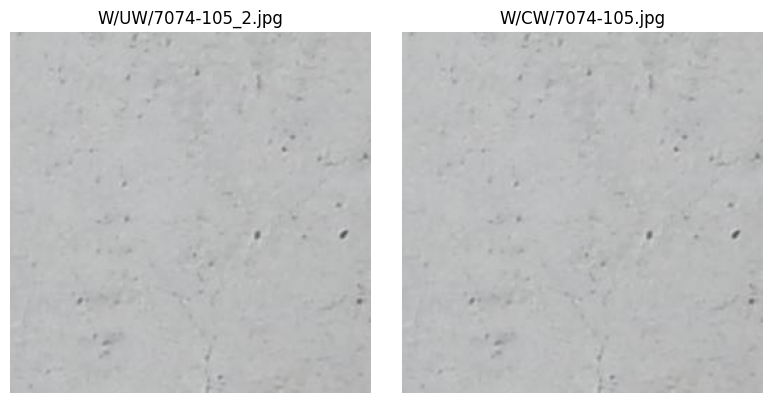

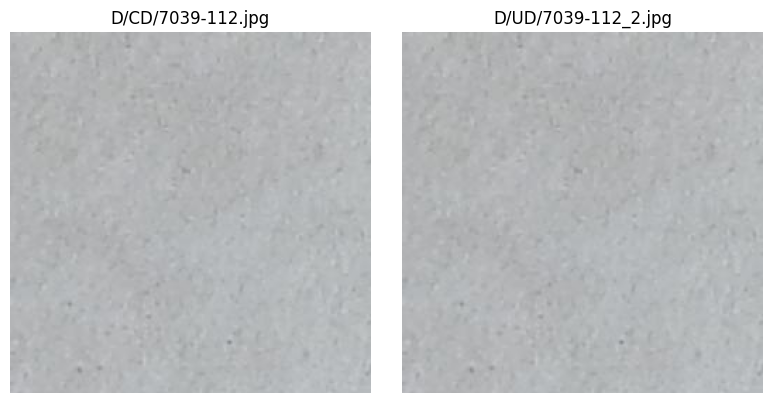

In [45]:

from PIL import Image
import matplotlib.pyplot as plt

conflicting_pairs = [
    (
        "/content/InfraScan_Dataset/W/UW/7074-105_2.jpg",
        "/content/InfraScan_Dataset/W/CW/7074-105.jpg"
    ),
    (
        "/content/InfraScan_Dataset/D/CD/7039-112.jpg",
        "/content/InfraScan_Dataset/D/UD/7039-112_2.jpg"
    )
]

for path1, path2 in conflicting_pairs:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    for ax, path in zip(axes, [path1, path2]):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(path.split("/InfraScan_Dataset/")[1])
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [46]:
# Exact duplicate pairs jinke labels conflict kar rahe hain
ambiguous_files = [
    "/content/InfraScan_Dataset/W/UW/7074-105_2.jpg",
    "/content/InfraScan_Dataset/W/CW/7074-105.jpg",
    "/content/InfraScan_Dataset/D/CD/7039-112.jpg",
    "/content/InfraScan_Dataset/D/UD/7039-112_2.jpg",
]

# Safety check: confirm all four files exist
import os

for path in ambiguous_files:
    print(
        "FOUND" if os.path.isfile(path) else "MISSING",
        path.split("/InfraScan_Dataset/")[-1]
    )

print("\nAmbiguous files marked:", len(ambiguous_files))
print("Original dataset files will NOT be deleted.")

FOUND W/UW/7074-105_2.jpg
FOUND W/CW/7074-105.jpg
FOUND D/CD/7039-112.jpg
FOUND D/UD/7039-112_2.jpg

Ambiguous files marked: 4
Original dataset files will NOT be deleted.


In [49]:
import os
import hashlib
import pandas as pd
from pathlib import Path

DATASET_DIR = "/content/InfraScan_Dataset"

# Step 1: Check dataset folder
if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset folder nahi mila: {DATASET_DIR}"
    )

# Step 2: Collect image paths
image_paths = sorted(
    str(p) for p in Path(DATASET_DIR).rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

print("Images found:", len(image_paths))

# Step 3: Calculate SHA-256 hash
def get_sha256(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()

# Step 4: Build records
hash_records = []

for i, path in enumerate(image_paths):
    relative_path = os.path.relpath(path, DATASET_DIR)
    parts = Path(relative_path).parts

    surface = parts[0] if len(parts) >= 3 else "Unknown"
    folder_label = parts[1] if len(parts) >= 3 else "Unknown"

    if folder_label in {"CD", "CP", "CW"}:
        binary_label = 1
    elif folder_label in {"UD", "UP", "UW"}:
        binary_label = 0
    else:
        binary_label = -1

    hash_records.append({
        "path": path,
        "relative_path": relative_path,
        "sha256": get_sha256(path),
        "surface": surface,
        "folder_label": folder_label,
        "binary_label": binary_label
    })

    if (i + 1) % 5000 == 0:
        print(f"Processed {i + 1}/{len(image_paths)} images")

# Step 5: Create DataFrame
hash_df = pd.DataFrame(hash_records)

print("\n--- HASH SUMMARY ---")
print("Total images:", len(hash_df))
print("Unique exact image contents:", hash_df["sha256"].nunique())
print(
    "Extra exact copies:",
    len(hash_df) - hash_df["sha256"].nunique()
)
print(
    "Rows with unknown labels:",
    (hash_df["binary_label"] == -1).sum()
)

display(hash_df.head())

Images found: 56092
Processed 5000/56092 images
Processed 10000/56092 images
Processed 15000/56092 images
Processed 20000/56092 images
Processed 25000/56092 images
Processed 30000/56092 images
Processed 35000/56092 images
Processed 40000/56092 images
Processed 45000/56092 images
Processed 50000/56092 images
Processed 55000/56092 images

--- HASH SUMMARY ---
Total images: 56092
Unique exact image contents: 56079
Extra exact copies: 13
Rows with unknown labels: 0


,path,relative_path,sha256,surface,folder_label,binary_label
0,/content/InfraScan_Dataset/D/CD/7001-115.jpg,D/CD/7001-115.jpg,f53597180101e3c17e2ee613f660c6b53b96e5218019ba...,D,CD,1
1,/content/InfraScan_Dataset/D/CD/7001-139.jpg,D/CD/7001-139.jpg,4c96684818bb3b154b54279667f20cb31c95223496272f...,D,CD,1
2,/content/InfraScan_Dataset/D/CD/7001-151.jpg,D/CD/7001-151.jpg,3922d9a2c4ea4e94e39f067cd029e98749ebe9cd1f3ad2...,D,CD,1
3,/content/InfraScan_Dataset/D/CD/7001-157.jpg,D/CD/7001-157.jpg,ab3b70d01f470ad9afd3eb535749e207009c432e2aaba4...,D,CD,1
4,/content/InfraScan_Dataset/D/CD/7001-169.jpg,D/CD/7001-169.jpg,c8afea5de74d0b358875bc2c3ca4bf2db5779d477fe4de...,D,CD,1


In [50]:
# Same SHA-256 hash wali images ko group karo
duplicate_df = hash_df[
    hash_df.duplicated("sha256", keep=False)
].copy()

duplicate_df = duplicate_df.sort_values(
    ["sha256", "relative_path"]
)

# Har duplicate group ka summary
group_summary = (
    duplicate_df.groupby("sha256")
    .agg(
        group_size=("path", "size"),
        files=("relative_path", list),
        labels=("binary_label", lambda x: sorted(set(x))),
        surfaces=("surface", lambda x: sorted(set(x)))
    )
    .reset_index()
)

# Jahan same exact image ke labels conflict karte hain
conflicts = group_summary[
    group_summary["labels"].apply(len) > 1
]

print("Exact duplicate groups:", len(group_summary))
print(
    "Files belonging to duplicate groups:",
    len(duplicate_df)
)
print("Groups with conflicting labels:", len(conflicts))

print("\n--- DUPLICATE GROUP DETAILS ---")
display(group_summary[["group_size", "files", "labels", "surfaces"]])

print("\n--- CONFLICTING LABEL GROUPS ---")
display(conflicts[["group_size", "files", "labels", "surfaces"]])

Exact duplicate groups: 13
Files belonging to duplicate groups: 26
Groups with conflicting labels: 2

--- DUPLICATE GROUP DETAILS ---


,group_size,files,labels,surfaces
0,2,"[D/UD/7053-36.jpg, D/UD/7053-36_2.jpg]",[0],[D]
1,2,"[D/CD/7039-113.jpg, D/CD/7039-113_2.jpg]",[1],[D]
2,2,"[D/CD/7039-111.jpg, D/CD/7039-111_2.jpg]",[1],[D]
3,2,"[D/UD/7053-89.jpg, D/UD/7053-89_2.jpg]",[0],[D]
4,2,"[D/UD/7053-90.jpg, D/UD/7053-90_2.jpg]",[0],[D]
5,2,"[D/CD/7039-110.jpg, D/CD/7039-110_2.jpg]",[1],[D]
6,2,"[D/UD/7053-54.jpg, D/UD/7053-54_2.jpg]",[0],[D]
7,2,"[D/CD/7039-112.jpg, D/UD/7039-112_2.jpg]","[0, 1]",[D]
8,2,"[D/UD/7053-18.jpg, D/UD/7053-18_2.jpg]",[0],[D]
9,2,"[W/CW/7074-105.jpg, W/UW/7074-105_2.jpg]","[0, 1]",[W]



--- CONFLICTING LABEL GROUPS ---


,group_size,files,labels,surfaces
7,2,"[D/CD/7039-112.jpg, D/UD/7039-112_2.jpg]","[0, 1]",[D]
9,2,"[W/CW/7074-105.jpg, W/UW/7074-105_2.jpg]","[0, 1]",[W]


In [51]:
# Step 1: Identify all conflicting exact-image hashes
conflict_hashes = set(conflicts["sha256"])

# Step 2: Mark ambiguous files for exclusion
hash_df["exclude_ambiguous"] = hash_df["sha256"].isin(
    conflict_hashes
)

# Step 3: Keep only one copy of each exact image
# Conflicting hashes are excluded entirely.
hash_df["keep_for_baseline"] = ~hash_df["exclude_ambiguous"]

# For same-label duplicates, keep the first path in sorted order.
safe_df = hash_df[hash_df["keep_for_baseline"]].copy()

safe_df = safe_df.sort_values("relative_path")

safe_df["keep_for_baseline"] = ~safe_df.duplicated(
    "sha256",
    keep="first"
)

# Step 4: Summary
print("Original images:", len(hash_df))
print("Ambiguous images excluded:", int(hash_df["exclude_ambiguous"].sum()))
print(
    "Images retained after duplicate removal:",
    int(safe_df["keep_for_baseline"].sum())
)
print(
    "Consistent duplicate copies skipped:",
    int((~safe_df["keep_for_baseline"]).sum())
)

# Step 5: Save the manifest; original dataset stays unchanged.
manifest_path = "/content/InfraScan_EDA_Results/clean_manifest.csv"
os.makedirs(os.path.dirname(manifest_path), exist_ok=True)

hash_df["split_group"] = hash_df["sha256"]

hash_df["status"] = "candidate"
hash_df.loc[hash_df["exclude_ambiguous"], "status"] = "exclude_ambiguous"

# Same-label exact copies can share a group and must not cross splits.
hash_df.to_csv(manifest_path, index=False)

print("\nManifest saved:", manifest_path)

Original images: 56092
Ambiguous images excluded: 4
Images retained after duplicate removal: 56077
Consistent duplicate copies skipped: 11

Manifest saved: /content/InfraScan_EDA_Results/clean_manifest.csv


In [52]:
from sklearn.model_selection import train_test_split
import pandas as pd
import os

# Step 1: Load the manifest
manifest_path = "/content/InfraScan_EDA_Results/clean_manifest.csv"
df = pd.read_csv(manifest_path)

# Step 2: Exclude ambiguous images
df = df[df["status"] != "exclude_ambiguous"].copy()

# Step 3: Keep only one copy per exact image
df = df.sort_values("relative_path")
df = df.drop_duplicates(subset="sha256", keep="first").copy()

# Step 4: Split 80% train and 20% validation
# Exact duplicates have already been deduplicated.
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["binary_label"]
)

# Step 5: Check for leakage
train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
overlap = train_hashes.intersection(val_hashes)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Exact duplicate leakage:", len(overlap))

print("\nTraining class distribution:")
print(train_df["binary_label"].map({
    0: "Uncracked",
    1: "Cracked"
}).value_counts())

print("\nValidation class distribution:")
print(val_df["binary_label"].map({
    0: "Uncracked",
    1: "Cracked"
}).value_counts())

# Save split manifests
output_dir = "/content/InfraScan_EDA_Results"
train_df.to_csv(f"{output_dir}/train_manifest.csv", index=False)
val_df.to_csv(f"{output_dir}/validation_manifest.csv", index=False)

print("\nSplit manifests saved successfully.")

Train images: 44861
Validation images: 11216
Exact duplicate leakage: 0

Training class distribution:
binary_label
Uncracked    38078
Cracked       6783
Name: count, dtype: int64

Validation class distribution:
binary_label
Uncracked    9520
Cracked      1696
Name: count, dtype: int64

Split manifests saved successfully.


In [53]:
# Check whether near-duplicate candidate pairs cross the split boundary.
# Uses the existing `near_duplicates` DataFrame from the earlier pHash analysis.

train_paths = set(train_df["path"])
val_paths = set(val_df["path"])

if "near_duplicates" not in globals():
    print("near_duplicates DataFrame not found.")
    print("We will need to reload or recreate the near-duplicate candidate list.")
else:
    cross_split_pairs = near_duplicates[
        (
            near_duplicates["path1"].isin(train_paths)
            & near_duplicates["path2"].isin(val_paths)
        )
        |
        (
            near_duplicates["path2"].isin(train_paths)
            & near_duplicates["path1"].isin(val_paths)
        )
    ].copy()

    print("Near-duplicate candidate pairs crossing splits:",
          len(cross_split_pairs))

    if len(cross_split_pairs) > 0:
        display(cross_split_pairs.head(20))
    else:
        print("No cross-split pairs found in the current candidate list.")

Near-duplicate candidate pairs crossing splits: 122


,path1,path2,hash_distance,label1,label2,binary1,binary2
11,/content/InfraScan_Dataset/D/UD/7033-239.jpg,/content/InfraScan_Dataset/P/CP/062-104.jpg,0,UD,CP,Uncracked,Cracked
19,/content/InfraScan_Dataset/D/UD/7014-118.jpg,/content/InfraScan_Dataset/P/UP/033-12.jpg,2,UD,UP,Uncracked,Uncracked
21,/content/InfraScan_Dataset/P/CP/027-59_2.jpg,/content/InfraScan_Dataset/P/UP/063-71.jpg,2,CP,UP,Cracked,Uncracked
22,/content/InfraScan_Dataset/P/CP/062-104.jpg,/content/InfraScan_Dataset/W/CW/7071-84.jpg,2,CP,CW,Cracked,Cracked
26,/content/InfraScan_Dataset/P/UP/034-83.jpg,/content/InfraScan_Dataset/W/CW/7119-69.jpg,2,UP,CW,Uncracked,Cracked
27,/content/InfraScan_Dataset/P/UP/088-212.jpg,/content/InfraScan_Dataset/W/UW/7100-21.jpg,2,UP,UW,Uncracked,Uncracked
28,/content/InfraScan_Dataset/W/CW/7119-69.jpg,/content/InfraScan_Dataset/W/UW/7134-146.jpg,2,CW,UW,Cracked,Uncracked
31,/content/InfraScan_Dataset/D/UD/7014-118.jpg,/content/InfraScan_Dataset/P/CP/092-63.jpg,2,UD,CP,Uncracked,Cracked
32,/content/InfraScan_Dataset/P/UP/026-29.jpg,/content/InfraScan_Dataset/W/CW/7085-62.jpg,2,UP,CW,Uncracked,Cracked
33,/content/InfraScan_Dataset/D/UD/7033-239.jpg,/content/InfraScan_Dataset/P/UP/078-2.jpg,2,UD,UP,Uncracked,Uncracked


Reviewing 8 pairs
Opposite-label pairs among these: 8


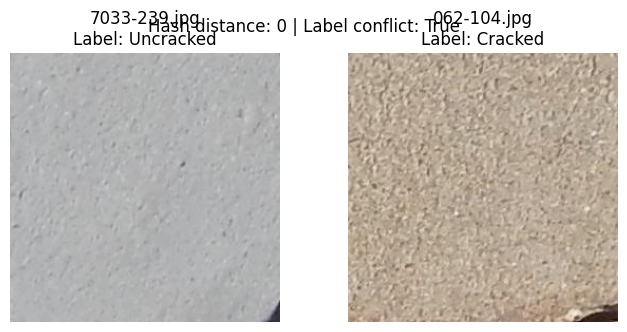

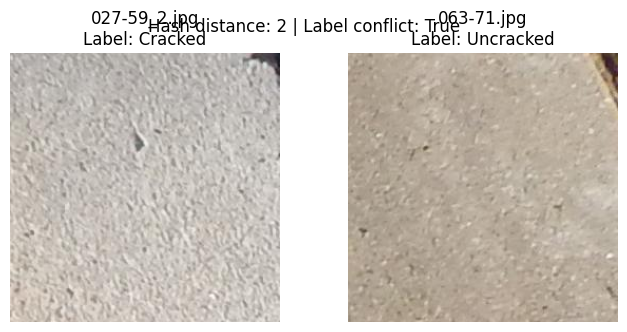

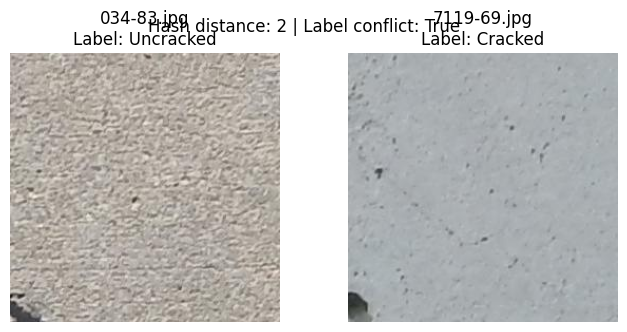

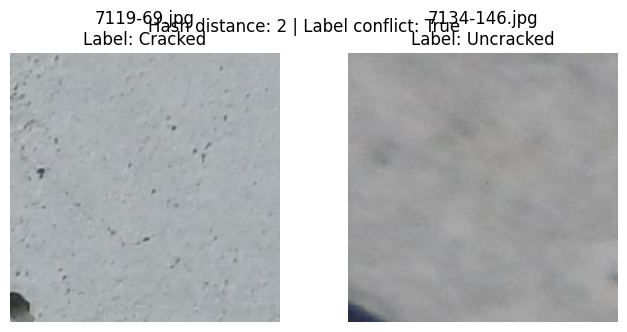

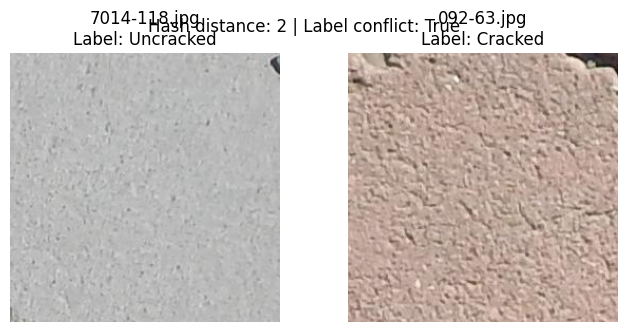

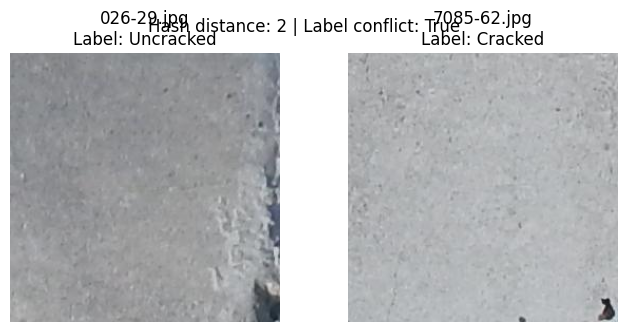

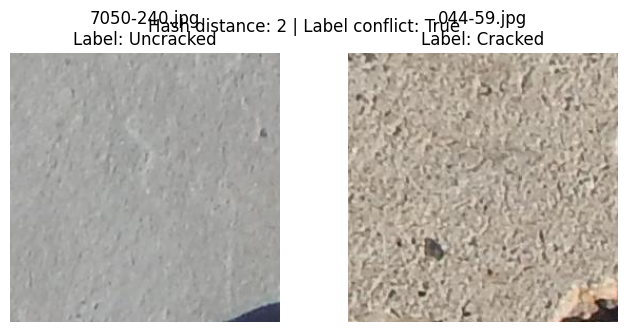

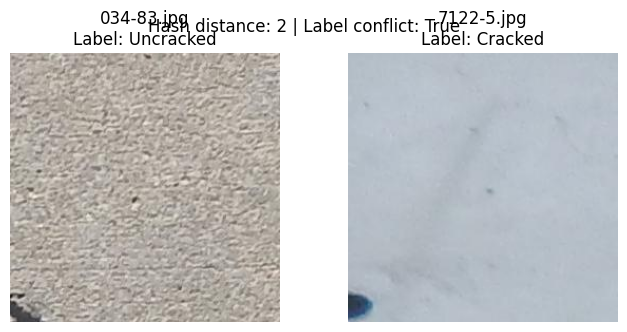

In [54]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Prioritize:
# 1. Different labels
# 2. Smaller perceptual hash distance
review_df = cross_split_pairs.copy()

review_df["label_conflict"] = (
    review_df["binary1"] != review_df["binary2"]
)

review_df = review_df.sort_values(
    ["label_conflict", "hash_distance"],
    ascending=[False, True]
)

# Inspect the first 8 highest-priority pairs
review_sample = review_df.head(8)

print("Reviewing", len(review_sample), "pairs")
print("Opposite-label pairs among these:",
      int(review_sample["label_conflict"].sum()))

for _, row in review_sample.iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

    for ax, path, label in [
        (axes[0], row["path1"], row["binary1"]),
        (axes[1], row["path2"], row["binary2"])
    ]:
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f'{os.path.basename(path)}\nLabel: {label}'
        )
        ax.axis("off")

    fig.suptitle(
        f'Hash distance: {row["hash_distance"]} | '
        f'Label conflict: {row["label_conflict"]}'
    )

In [55]:
# Count cross-split candidates by perceptual hash distance
print("Cross-split candidate pairs:", len(cross_split_pairs))

print("\nPairs by hash distance:")
print(
    cross_split_pairs["hash_distance"]
    .value_counts()
    .sort_index()
)

print("\nDistance 0 pairs:")
display(
    cross_split_pairs[
        cross_split_pairs["hash_distance"] == 0
    ][
        ["path1", "path2", "hash_distance", "binary1", "binary2"]
    ]
)

Cross-split candidate pairs: 122

Pairs by hash distance:
hash_distance
0     1
2    39
4    82
Name: count, dtype: int64

Distance 0 pairs:


,path1,path2,hash_distance,binary1,binary2
11,/content/InfraScan_Dataset/D/UD/7033-239.jpg,/content/InfraScan_Dataset/P/CP/062-104.jpg,0,Uncracked,Cracked


In [56]:
import os
import pandas as pd

output_dir = "/content/InfraScan_EDA_Results"
os.makedirs(output_dir, exist_ok=True)

# Save the current provisional split
train_df.to_csv(
    f"{output_dir}/train_manifest_provisional.csv",
    index=False
)

val_df.to_csv(
    f"{output_dir}/validation_manifest_provisional.csv",
    index=False
)

# Save near-duplicate cross-split candidates for review
cross_split_pairs.to_csv(
    f"{output_dir}/cross_split_near_duplicate_review.csv",
    index=False
)

# Final checks
assert set(train_df["sha256"]).isdisjoint(
    set(val_df["sha256"])
)

assert len(train_df) + len(val_df) == 56077

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Exact hash overlap:", len(
    set(train_df["sha256"]) & set(val_df["sha256"])
))
print("Near-duplicate candidates flagged:", len(cross_split_pairs))
print("Provisional manifests and review list saved.")

Train images: 44861
Validation images: 11216
Exact hash overlap: 0
Near-duplicate candidates flagged: 122
Provisional manifests and review list saved.


In [57]:
import os
import zipfile
from google.colab import files

results_dir = "/content/InfraScan_EDA_Results"
zip_path = "/content/InfraScan_EDA_Results.zip"

# Package the EDA outputs, reports and manifests.
# Dataset images are NOT included.
with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:
    for root, dirs, filenames in os.walk(results_dir):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            arcname = os.path.relpath(full_path, results_dir)
            zipf.write(full_path, arcname)

print("Updated EDA ZIP created:", zip_path)
print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

files.download(zip_path)

Updated EDA ZIP created: /content/InfraScan_EDA_Results.zip
ZIP size (MB): 10.33


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>